In [1]:
import shap
import numpy as np
import pandas as pd
import json
from tensorflow.keras.models import load_model
from sklearn.preprocessing import StandardScaler

# Load the ORIGINAL primary CNN model (14-class, 23-feature)
cnn_model = load_model('../models/cnn_model.h5')

# Load the same data used to train it
X_train = pd.read_csv('../data/processed/X_train.csv')
X_test = pd.read_csv('../data/processed/X_test.csv')
y_test = np.load('../data/processed/y_test.npy')

with open('../data/processed/label_mapping.json') as f:
    label_mapping = json.load(f)

int_to_label = {v: k for k, v in label_mapping.items()}

# Recreate the exact same scaling used during CNN training
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train.values)
X_test_scaled = scaler.transform(X_test.values)

print("CNN model loaded, data prepared.")

C:\Users\LOQ\anaconda3\envs\traffic-classifier\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CNN model loaded, data prepared.


In [2]:
# Reshape for CNN input: (samples, 23, 1)
X_train_cnn = X_train_scaled.reshape(X_train_scaled.shape[0], 23, 1)
X_test_cnn = X_test_scaled.reshape(X_test_scaled.shape[0], 23, 1)

# Background sample (used as SHAP's reference baseline) — keep small, e.g. 100
background = X_train_cnn[np.random.choice(X_train_cnn.shape[0], 100, replace=False)]

# Sample to explain — 150-200 is more reliable than Fida's 50, still fast enough
explain_sample_idx = np.random.choice(X_test_cnn.shape[0], 150, replace=False)
X_explain = X_test_cnn[explain_sample_idx]

print("Background shape:", background.shape)
print("Explain sample shape:", X_explain.shape)

Background shape: (100, 23, 1)
Explain sample shape: (150, 23, 1)


In [3]:
# KernelSHAP needs a flat 2D input function, not 3D — wrap the CNN's predict function
def cnn_predict_flat(X_flat):
    X_reshaped = X_flat.reshape(X_flat.shape[0], 23, 1)
    return cnn_model.predict(X_reshaped, verbose=0)

# Flatten background and explain samples to 2D for KernelExplainer
background_flat = background.reshape(background.shape[0], 23)
X_explain_flat = X_explain.reshape(X_explain.shape[0], 23)

explainer_cnn = shap.KernelExplainer(cnn_predict_flat, background_flat)

print("Running KernelSHAP — this will take several minutes, please wait...")
shap_values_cnn = explainer_cnn.shap_values(X_explain_flat, nsamples=100)

print("KernelSHAP values calculated successfully!")

Running KernelSHAP — this will take several minutes, please wait...


100%|██████████| 150/150 [01:53<00:00,  1.32it/s]

KernelSHAP values calculated successfully!


Number of classes explained: 150
Shape per class: (23, 14)


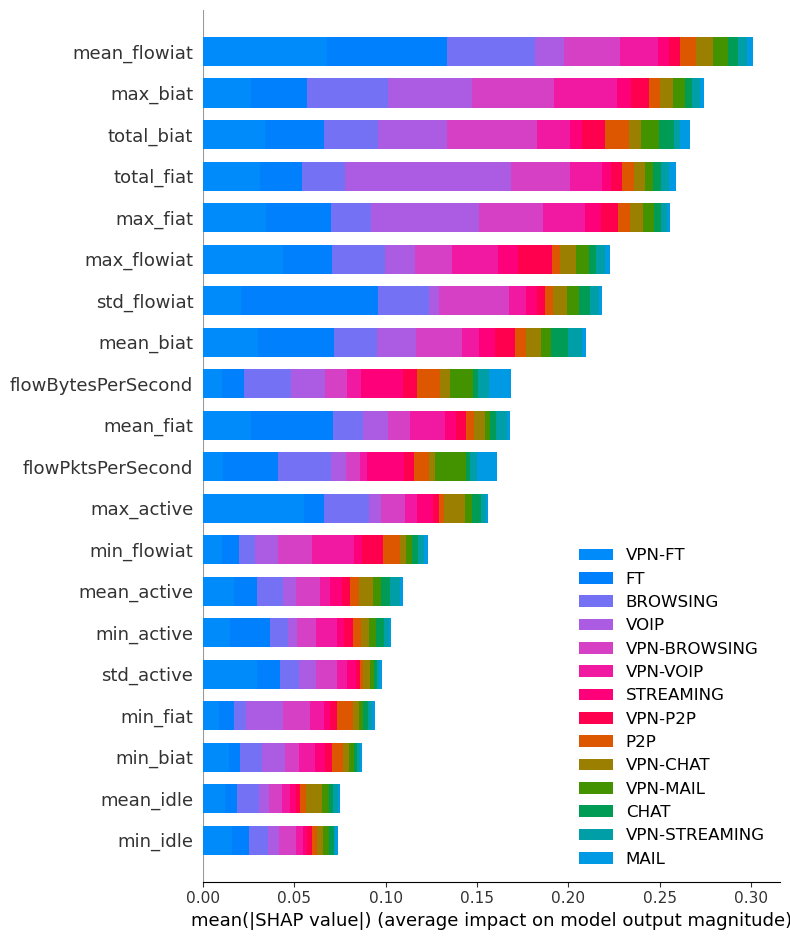

In [4]:
import matplotlib.pyplot as plt

# shap_values_cnn is a list of arrays (one per class) for multi-class KernelSHAP
print("Number of classes explained:", len(shap_values_cnn))
print("Shape per class:", shap_values_cnn[0].shape)

# Global summary plot - averaged feature importance across all classes
shap.summary_plot(
    shap_values_cnn,
    X_explain_flat,
    feature_names=X_train.columns.tolist(),
    plot_type="bar",
    class_names=[int_to_label[i] for i in range(14)]
)

In [6]:
print("Type:", type(shap_values_cnn))
if isinstance(shap_values_cnn, list):
    print("It's a list of", len(shap_values_cnn), "arrays")
    print("Shape of first element:", shap_values_cnn[0].shape)
else:
    print("It's a single array with shape:", shap_values_cnn.shape)

Type: <class 'numpy.ndarray'>
It's a single array with shape: (150, 23, 14)


Shape for FT class: (150, 23)


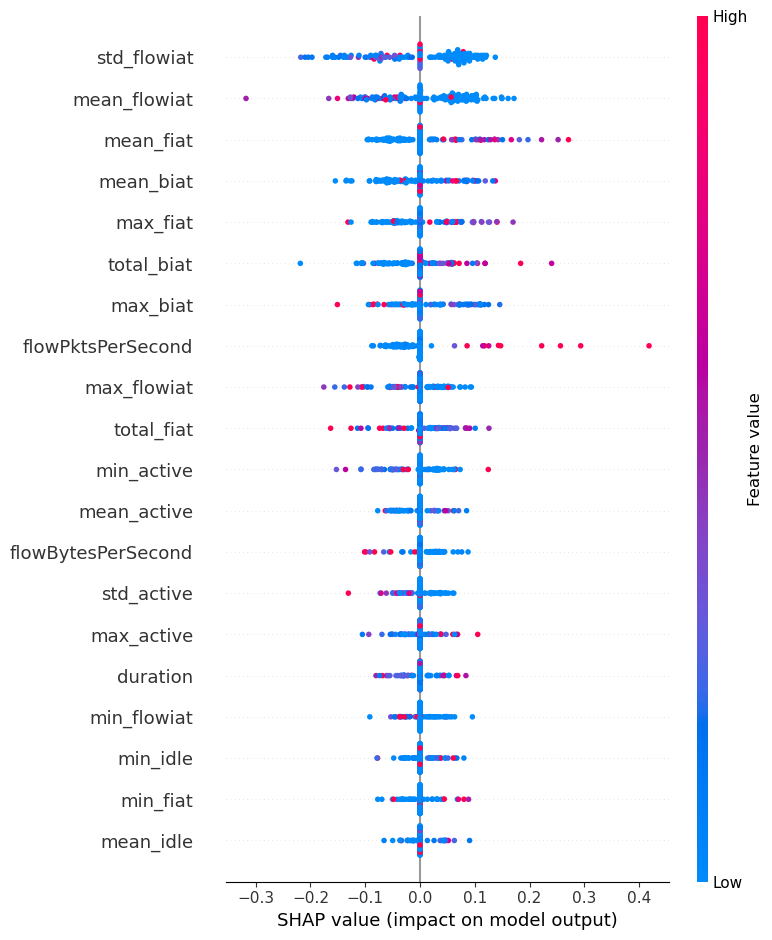

In [7]:
# Correct way to select class 2 (FT) from a (samples, features, classes) array
shap_values_ft = shap_values_cnn[:, :, 2]

print("Shape for FT class:", shap_values_ft.shape)  # should be (150, 23)

shap.summary_plot(
    shap_values_ft,
    X_explain_flat,
    feature_names=X_train.columns.tolist()
)

               Feature  Mean |SHAP value|
13        mean_flowiat           0.021482
6             max_biat           0.019581
2           total_biat           0.019031
1           total_fiat           0.018478
5             max_fiat           0.018272
12         max_flowiat           0.015896
14         std_flowiat           0.015587
8            mean_biat           0.014979
10  flowBytesPerSecond           0.012057
7            mean_fiat           0.011985
9    flowPktsPerSecond           0.011488
17          max_active           0.011155
11         min_flowiat           0.008810
16         mean_active           0.007828
15          min_active           0.007365
18          std_active           0.007005
3             min_fiat           0.006709
4             min_biat           0.006202
20           mean_idle           0.005351
19            min_idle           0.005261
0             duration           0.005023
21            max_idle           0.004314
22            std_idle           0

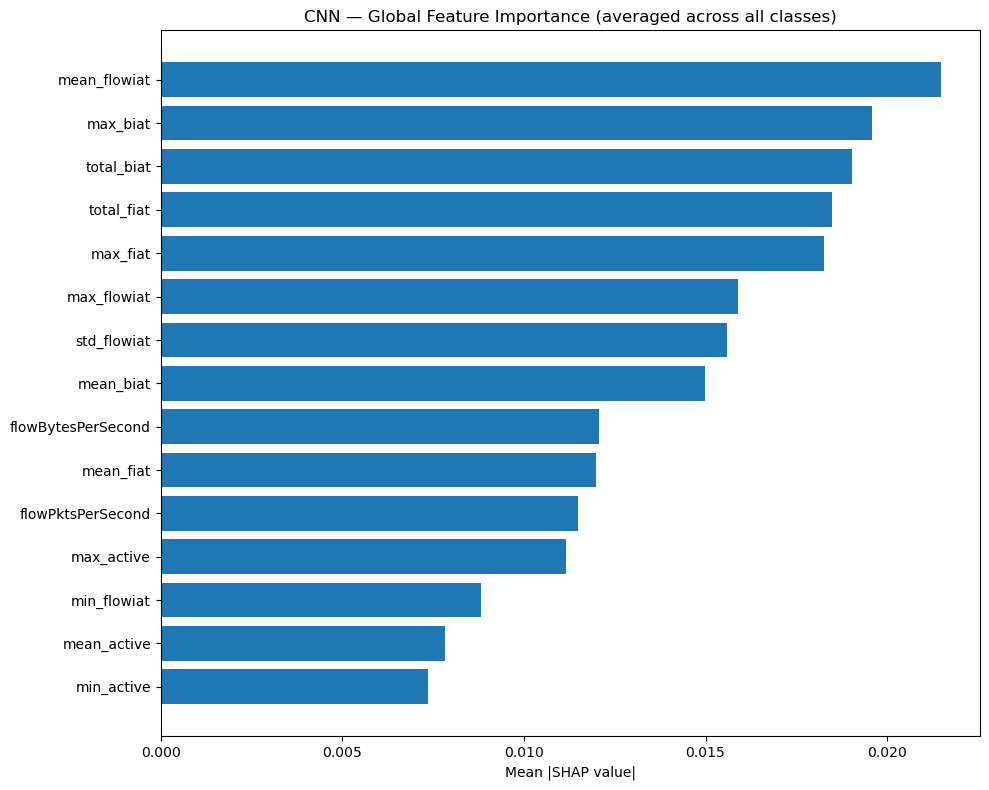

In [8]:
# Global importance across all classes - average absolute SHAP value per feature
import numpy as np

mean_abs_shap = np.abs(shap_values_cnn).mean(axis=(0, 2))  # average over samples AND classes

feature_importance_cnn = pd.DataFrame({
    "Feature": X_train.columns.tolist(),
    "Mean |SHAP value|": mean_abs_shap
}).sort_values("Mean |SHAP value|", ascending=False)

print(feature_importance_cnn)

plt.figure(figsize=(10, 8))
plt.barh(feature_importance_cnn["Feature"][:15][::-1], feature_importance_cnn["Mean |SHAP value|"][:15][::-1])
plt.xlabel("Mean |SHAP value|")
plt.title("CNN — Global Feature Importance (averaged across all classes)")
plt.tight_layout()
plt.show()

In [9]:
# Get CNN's actual predictions on the explained samples
cnn_preds_on_explain = np.argmax(cnn_model.predict(X_explain, verbose=0), axis=1)

# True labels for the same samples
y_true_explain = y_test[explain_sample_idx]

# Find a misclassified FT sample (true class 2), specifically confused with VPN-P2P (11) if possible
ft_confused_mask = (y_true_explain == 2) & (cnn_preds_on_explain != 2)
confused_indices = np.where(ft_confused_mask)[0]

print("Number of FT samples misclassified by CNN in this batch:", len(confused_indices))
if len(confused_indices) > 0:
    for idx in confused_indices[:5]:
        print(f"Sample {idx}: true=FT, predicted={int_to_label[cnn_preds_on_explain[idx]]}")

Number of FT samples misclassified by CNN in this batch: 6
Sample 12: true=FT, predicted=BROWSING
Sample 18: true=FT, predicted=VPN-P2P
Sample 32: true=FT, predicted=VPN-P2P
Sample 49: true=FT, predicted=VPN-P2P
Sample 60: true=FT, predicted=P2P


In [10]:
# Pick sample 18 (FT misclassified as VPN-P2P)
local_idx = 18

# Get SHAP values for THIS sample, for the VPN-P2P class (11) - i.e. why did the model lean toward VPN-P2P?
shap_values_local_vpnp2p = shap_values_cnn[local_idx, :, 11]

# Also grab the values for the TRUE class (FT, class 2), to see why it DIDN'T lean toward FT enough
shap_values_local_ft = shap_values_cnn[local_idx, :, 2]

# Build a comparison table
local_explanation = pd.DataFrame({
    "Feature": X_train.columns.tolist(),
    "Actual value": X_explain_flat[local_idx],
    "SHAP → VPN-P2P": shap_values_local_vpnp2p,
    "SHAP → FT (true class)": shap_values_local_ft
}).sort_values("SHAP → VPN-P2P", ascending=False)

print("Top features pushing toward VPN-P2P (the WRONG prediction):")
print(local_explanation.head(8))

print("\nBottom features (pushing AWAY from VPN-P2P, i.e. toward other classes):")
print(local_explanation.tail(5))

Top features pushing toward VPN-P2P (the WRONG prediction):
              Feature  Actual value  SHAP → VPN-P2P  SHAP → FT (true class)
22           std_idle     -0.252313        0.034510                0.000000
6            max_biat     -0.454535        0.032113                0.000000
9   flowPktsPerSecond     -0.138686        0.026614                0.000000
1          total_fiat     -0.637655        0.024690                0.014936
5            max_fiat     -0.357962        0.022325                0.000000
7           mean_fiat     -0.346391        0.020637               -0.096411
21           max_idle     -0.361808        0.018445                0.000000
0            duration     -0.653804        0.017162                0.013114

Bottom features (pushing AWAY from VPN-P2P, i.e. toward other classes):
        Feature  Actual value  SHAP → VPN-P2P  SHAP → FT (true class)
16  mean_active     -0.335937             0.0                0.000000
18   std_active     -0.265721             0

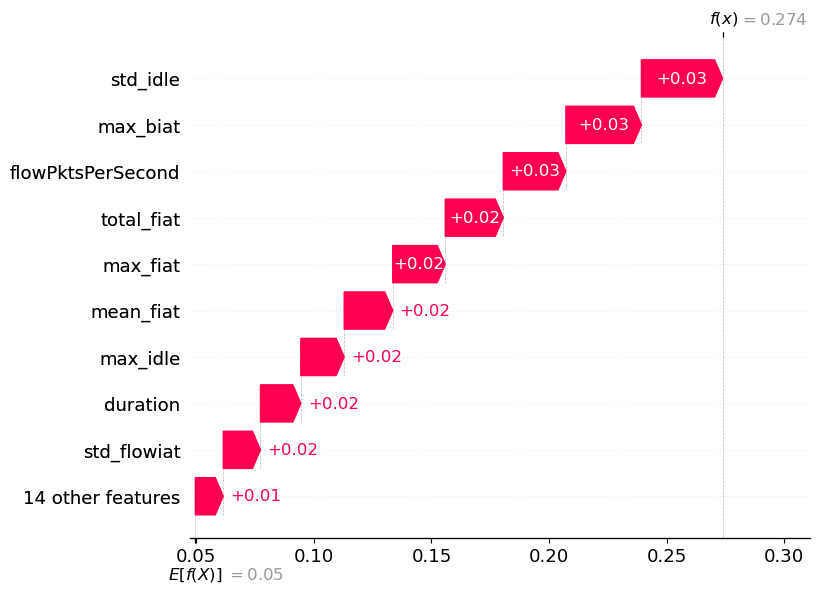

In [11]:
shap.plots._waterfall.waterfall_legacy(
    explainer_cnn.expected_value[11],  # baseline value for VPN-P2P class
    shap_values_local_vpnp2p,
    feature_names=X_train.columns.tolist(),
    max_display=10
)